# EDA dữ liệu bệnh tim — có thể chạy lại

Notebook độc lập với API/DB, đọc `data/raw_data/heart_disease_uci.csv` và xuất kết quả vào
`notebook/eda_outputs/`. Chạy **Restart Kernel & Run All** từ thư mục gốc hoặc `notebook/`.
Cài môi trường bằng `pip install -r notebook/requirements-eda.txt` từ thư mục gốc.

Phân tích mô tả phục vụ nghiên cứu dữ liệu, không suy ra quan hệ nhân quả hay hiệu quả chẩn đoán.
Giữ dữ liệu gốc; các lựa chọn xử lý thiếu/outlier dưới đây là gợi ý để kiểm chứng trên tập train.

## 1. Import, nạp dữ liệu và kiểm tra chất lượng

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import platform
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

SEED = 42
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/raw_data/heart_disease_uci.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ thư mục dự án hoặc notebook/')
DATA_PATH = ROOT / 'data/raw_data/heart_disease_uci.csv'
OUTPUT_DIR = ROOT / 'notebook/eda_outputs'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

df = pd.read_csv(DATA_PATH, na_values=['?', 'NA', 'N/A', ''])
assert not df.empty, 'Dataset rỗng'
assert {'id', 'num', 'dataset'}.issubset(df.columns), 'Thiếu cột bắt buộc'
assert df['num'].dropna().isin([0, 1, 2, 3, 4]).all(), 'Nhãn num không hợp lệ'
continuous = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
categorical = ['sex', 'dataset', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
quality = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean().mul(100),
    'unique_non_null': df.nunique(),
}).sort_values('missing_percent', ascending=False)
# ID thường là duy nhất nên cũng kiểm tra trùng nội dung khi bỏ ID.
content_columns = [c for c in df.columns if c != 'id']
quality_summary = {
    'rows': len(df), 'columns': len(df.columns),
    'duplicate_full_rows': int(df.duplicated().sum()),
    'duplicate_ids': int(df['id'].duplicated().sum()),
    'duplicate_rows_without_id': int(df.duplicated(subset=content_columns).sum()),
    'missing_target': int(df['num'].isna().sum()),
}
display(df.head(), pd.Series(quality_summary, name='value'), quality)
# Các số 0 đáng xem lại được báo cáo riêng, chưa tự thay đổi thành NaN.
zero_counts = df[['trestbps', 'chol', 'thalch']].eq(0).sum().rename('zero_count')
display(zero_counts)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


rows                         920
columns                       16
duplicate_full_rows            0
duplicate_ids                  0
duplicate_rows_without_id      2
missing_target                 0
Name: value, dtype: int64

,dtype,missing_count,missing_percent,unique_non_null
ca,float64,611,66.413043,4
thal,object,486,52.826087,3
slope,object,309,33.586957,3
fbs,object,90,9.782609,2
oldpeak,float64,62,6.739130,53
trestbps,float64,59,6.413043,61
exang,object,55,5.978261,2
thalch,float64,55,5.978261,119
chol,float64,30,3.260870,217
restecg,object,2,0.217391,3


trestbps      1
chol        172
thalch        0
Name: zero_count, dtype: int64

## 2. Thống kê mô tả và phân phối theo nguồn dữ liệu

In [2]:
# Không đưa ID vào thống kê trung bình/tương quan.
numeric_columns = df.select_dtypes(include=np.number).columns.difference(['id']).tolist()
descriptive = df[numeric_columns].describe().T
# describe() đã có mean/std/quantiles; thêm median/skew rõ ràng.
descriptive['median'] = df[numeric_columns].median()
descriptive['skew'] = df[numeric_columns].skew()
category_counts = pd.concat([
    df[c].fillna('<missing>').astype(str).value_counts(dropna=False)
      .rename_axis('value').reset_index(name='count').assign(column=c)
    for c in categorical
], ignore_index=True)[['column', 'value', 'count']]
target_distribution = df['num'].value_counts(dropna=False).sort_index().rename('count')
source_summary = df.groupby('dataset', dropna=False).agg(
    rows=('id', 'size'), mean_age=('age', 'mean'),
    labeled_rows=('num', 'count'),
    positive_labels=('num', lambda s: int(s.dropna().gt(0).sum())),
)
source_summary['positive_fraction'] = source_summary['positive_labels'] / source_summary['labeled_rows']
missing_by_source = df.groupby('dataset', dropna=False)[continuous + ['ca', 'thal']].agg(lambda s: s.isna().mean())
display(descriptive, category_counts, target_distribution, source_summary, missing_by_source)

,count,mean,std,min,25%,50%,75%,max,median,skew
age,920.0,53.510870,9.424685,28.0,47.0,54.0,60.0,77.0,54.0,-0.195994
ca,309.0,0.676375,0.935653,0.0,0.0,0.0,1.0,3.0,0.0,1.165978
chol,890.0,199.130337,110.780810,0.0,175.0,223.0,268.0,603.0,223.0,-0.613836
num,920.0,0.995652,1.142693,0.0,0.0,1.0,2.0,4.0,1.0,0.968880
oldpeak,858.0,0.878788,1.091226,-2.6,0.0,0.5,1.5,6.2,0.5,1.041427
thalch,865.0,137.545665,25.926276,60.0,120.0,140.0,157.0,202.0,140.0,-0.211119
trestbps,861.0,132.132404,19.066070,0.0,120.0,130.0,140.0,200.0,130.0,0.213334


,column,value,count
0,sex,Male,726
1,sex,Female,194
2,dataset,Cleveland,304
3,dataset,Hungary,293
4,dataset,VA Long Beach,200
5,dataset,Switzerland,123
6,cp,asymptomatic,496
7,cp,non-anginal,204
8,cp,atypical angina,174
9,cp,typical angina,46


num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64

,rows,mean_age,labeled_rows,positive_labels,positive_fraction
dataset,,,,,
Cleveland,304,54.351974,304,139,0.457237
Hungary,293,47.894198,293,106,0.361775
Switzerland,123,55.317073,123,115,0.934959
VA Long Beach,200,59.350000,200,149,0.745000


,age,trestbps,chol,thalch,oldpeak,ca,thal
dataset,,,,,,,
Cleveland,0.0,0.000000,0.000000,0.000000,0.00000,0.016447,0.009868
Hungary,0.0,0.003413,0.078498,0.003413,0.00000,0.989761,0.904437
Switzerland,0.0,0.016260,0.000000,0.008130,0.04878,0.959350,0.422764
VA Long Beach,0.0,0.280000,0.035000,0.265000,0.28000,0.990000,0.830000


## 3. Visualization: histogram, boxplot và correlation heatmap

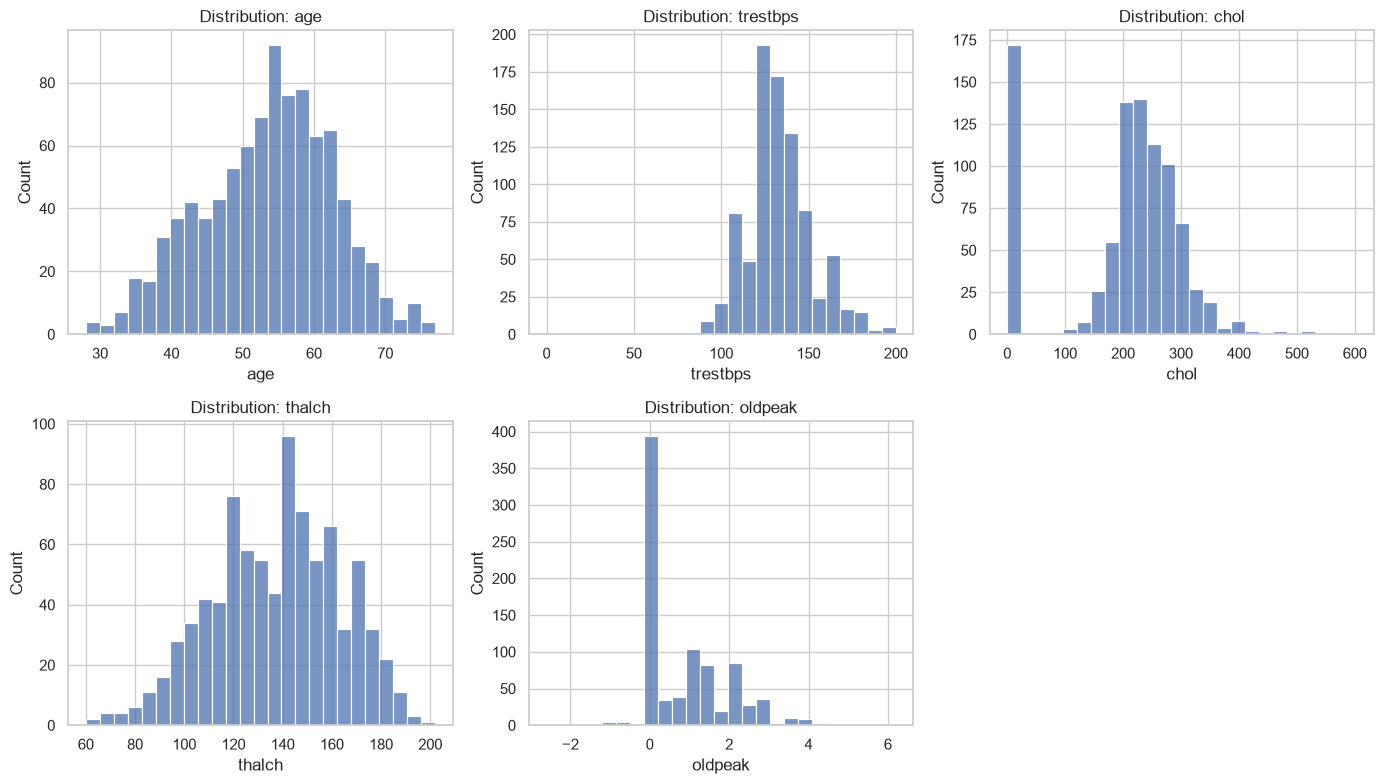

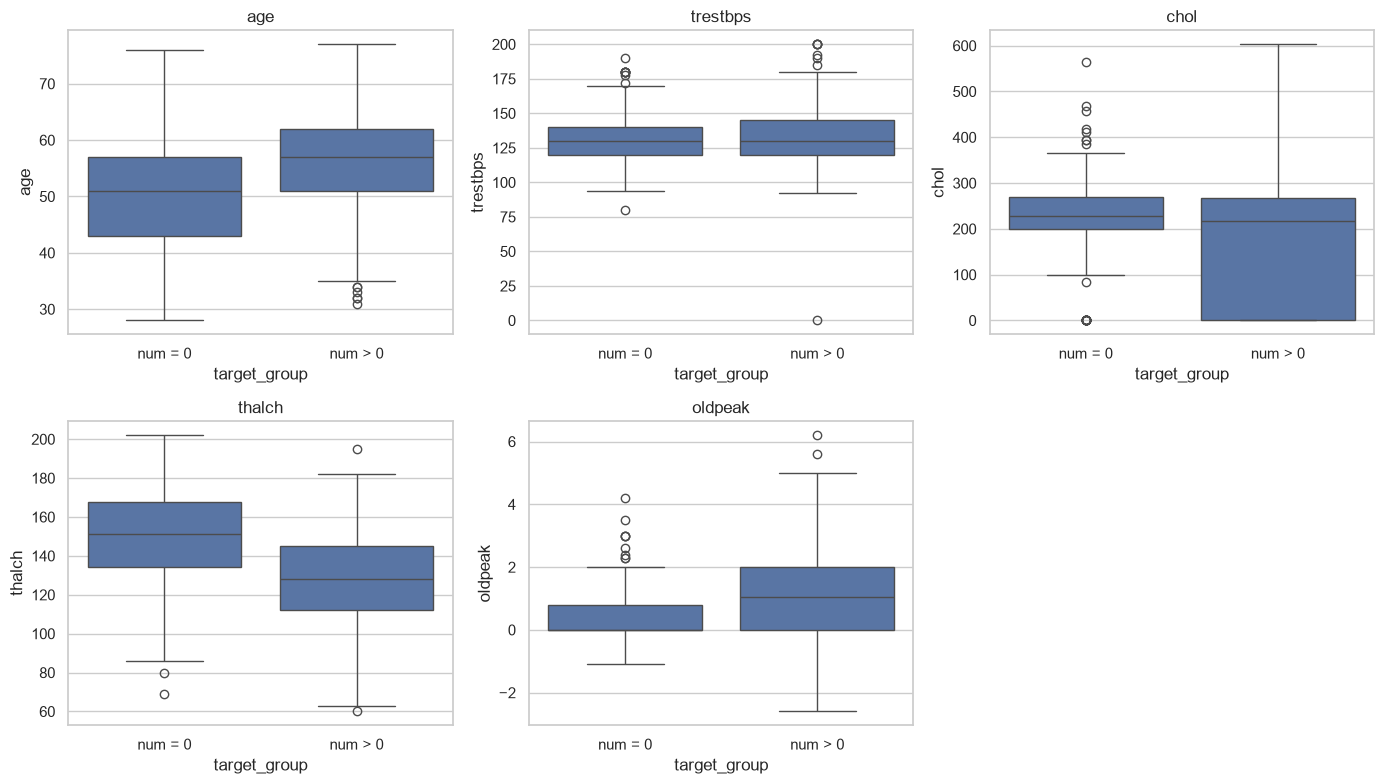

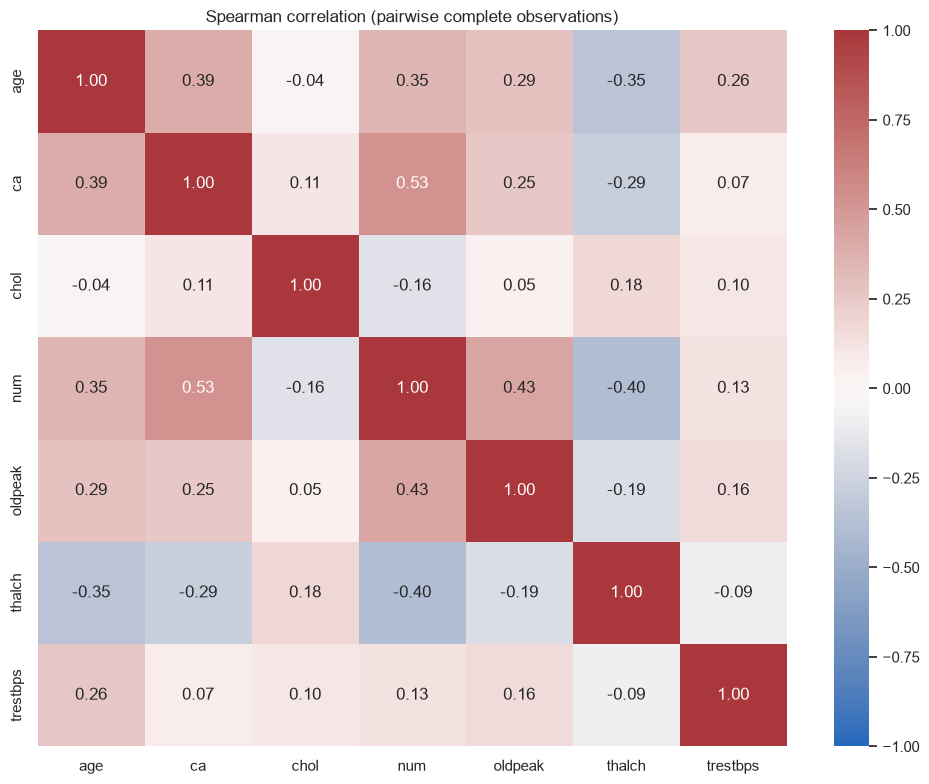

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.flat, continuous):
    sns.histplot(data=df, x=column, bins=25, ax=ax)
    ax.set_title(f'Distribution: {column}')
for ax in list(axes.flat)[len(continuous):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'histograms.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

plot_df = df.loc[df['num'].notna()].copy()
plot_df['target_group'] = np.where(plot_df['num'].gt(0), 'num > 0', 'num = 0')
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, column in zip(axes.flat, continuous):
    sns.boxplot(data=plot_df, x='target_group', y=column, ax=ax)
    ax.set_title(column)
for ax in list(axes.flat)[len(continuous):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'boxplots.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

correlation = df[numeric_columns].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Spearman correlation (pairwise complete observations)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'correlation_heatmap.png', dpi=160, bbox_inches='tight')
plt.show()
plt.close(fig)

## 4. Gợi ý feature engineering và ví dụ tránh leakage

- **Missing values:** thống kê theo nguồn; median cho số và giá trị riêng cho danh mục là baseline.
  Giữ cờ missing để đánh giá tác động; không xem giá trị thiếu là kết quả xét nghiệm bình thường.
- **Scaling:** `RobustScaler` cho biến liên tục. Mô hình cây thường không cần scaling;
  so sánh lựa chọn bằng cross-validation trên train.
- **Encoding:** `ca` là danh mục có thứ tự rời rạc; ví dụ này dùng one-hot cho ca và các danh mục khác.
  `handle_unknown='ignore'` cho dữ liệu mới.
- **Outliers:** IQR chỉ gắn cờ để xem xét, không tự xóa hàng. Xuất ngưỡng từ train để thử clipping
  nếu có cơ sở; không fit ngưỡng, scaler hoặc imputer trên test.
- **Target:** `num > 0` là nhãn nhị phân trong ví dụ. Loại `num`, ID và nguồn `dataset` khỏi X;
  không đưa nhãn hay điểm được tính từ nhãn vào feature.
- **Nguồn dữ liệu:** split ngẫu nhiên phân tầng chỉ minh họa. Khi đánh giá mô hình cần thêm
  validation theo bệnh viện/nguồn (`dataset`) và theo bệnh nhân nếu có ID bệnh nhân thực sự.
  ID hàng trong CSV chưa đảm bảo nhận diện bệnh nhân giữa các nguồn.

EDA toàn bộ dữ liệu ở trên chỉ mang tính mô tả. Ví dụ dưới không huấn luyện hay thay thế mô hình đang triển khai.

In [4]:
# Trùng nội dung có thể gây leakage giữa train/test trong ví dụ.
model_df = df.drop_duplicates(subset=content_columns).dropna(subset=['num']).copy()
X = model_df.drop(columns=['id', 'num', 'dataset']).copy()
y = model_df['num'].gt(0).astype('int8').rename('target')
cat_features = [c for c in categorical if c != 'dataset']
# Dùng kiểu chuỗi đồng nhất cho bool/số/danh mục, giữ NaN cho imputer.
for column in cat_features:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan).astype(object)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y,
)
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', RobustScaler()),
    ]), continuous),
    ('categorical', Pipeline([
        ('impute', SimpleImputer(strategy='constant', fill_value='<missing>')),
        ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ]), cat_features),
], remainder='drop')
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
assert np.isfinite(X_train_encoded).all() and np.isfinite(X_test_encoded).all()
assert set(X_train.index).isdisjoint(X_test.index)
assert not {'num', 'id', 'dataset'}.intersection(X.columns)

quartiles = X_train[continuous].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
outliers = pd.DataFrame({
    'q1': quartiles.loc[0.25], 'q3': quartiles.loc[0.75],
    'lower_bound': quartiles.loc[0.25] - 1.5 * iqr,
    'upper_bound': quartiles.loc[0.75] + 1.5 * iqr,
})
flags = X_train[continuous].lt(outliers['lower_bound']) | X_train[continuous].gt(outliers['upper_bound'])
outliers['train_outlier_count'] = flags.sum()
outliers['train_outlier_percent_non_missing'] = flags.sum().div(X_train[continuous].notna().sum()).mul(100)
display(outliers, pd.DataFrame({
    'split': ['train', 'test'], 'rows': [len(X_train), len(X_test)],
    'positive_fraction': [y_train.mean(), y_test.mean()],
}))
print('Encoded shapes:', X_train_encoded.shape, X_test_encoded.shape)

,q1,q3,lower_bound,upper_bound,train_outlier_count,train_outlier_percent_non_missing
age,47.0,60.0,27.50,79.50,0,0.000000
trestbps,120.0,140.0,90.00,170.00,23,3.362573
chol,174.0,269.0,31.50,411.50,146,20.592384
thalch,120.0,157.0,64.50,212.50,1,0.145560
oldpeak,0.0,1.5,-2.25,3.75,12,1.756955


,split,rows,positive_fraction
0,train,734,0.553134
1,test,184,0.554348


Encoded shapes: (734, 37) (184, 37)


## 5. Lưu kết quả EDA và metadata để tái sử dụng

In [5]:
tables = {
    'data_quality': quality, 'descriptive_statistics': descriptive,
    'category_counts': category_counts, 'target_distribution': target_distribution,
    'source_summary': source_summary, 'missing_by_source': missing_by_source,
    'zero_counts': zero_counts, 'spearman_correlation': correlation,
    'train_iqr_outliers': outliers,
}
for name, table in tables.items():
    table.to_csv(OUTPUT_DIR / f'{name}.csv', encoding='utf-8-sig')
# Snapshot nguyên bản sau khi parse missing; không ghi đè file nguồn.
df.to_csv(OUTPUT_DIR / 'data_snapshot.csv', index=False, encoding='utf-8-sig')
joblib.dump(preprocessor, OUTPUT_DIR / 'eda_preprocessor.joblib')
np.savez_compressed(
    OUTPUT_DIR / 'example_train_test.npz',
    X_train=X_train_encoded, X_test=X_test_encoded,
    y_train=y_train.to_numpy(), y_test=y_test.to_numpy(),
    train_rows=X_train.index.to_numpy(), test_rows=X_test.index.to_numpy(),
)
metadata = {
    **quality_summary,
    'source': str(DATA_PATH.relative_to(ROOT)),
    'source_sha256': hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'generated_at_utc': datetime.now(timezone.utc).isoformat(),
    'seed': SEED, 'test_size': 0.2,
    'target_definition': 'num > 0, missing labels excluded',
    'excluded_features': ['id', 'num', 'dataset'],
    'feature_names': feature_names.tolist(),
    'train_rows': len(X_train), 'test_rows': len(X_test),
    'outlier_handling': 'IQR thresholds fit on train; flags only; no clipping/deletion',
    'versions': {'python': platform.python_version(), 'pandas': pd.__version__,
                 'numpy': np.__version__, 'sklearn': sklearn.__version__},
}
(OUTPUT_DIR / 'summary.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
# Kiểm tra artifact có thể đọc lại, giữ đúng số hàng và số features.
saved = np.load(OUTPUT_DIR / 'example_train_test.npz')
assert saved['X_train'].shape == X_train_encoded.shape
assert json.loads((OUTPUT_DIR / 'summary.json').read_text(encoding='utf-8'))['rows'] == len(df)
print('Saved artifacts:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name)

Saved artifacts:
.ipython
boxplots.png
category_counts.csv
correlation_heatmap.png
data_quality.csv
data_snapshot.csv
descriptive_statistics.csv
eda_preprocessor.joblib
example_train_test.npz
heart_disease_eda.executed.ipynb
histograms.png
missing_by_source.csv
source_summary.csv
spearman_correlation.csv
summary.json
target_distribution.csv
train_iqr_outliers.csv
zero_counts.csv
